Boolean path operations, text outlines and baked transforms.

Boolean operators run on skia path ops.
Run it as ``python boolean_ops.py [OUTPUT_DIR]`` or open ``boolean_ops.ipynb`` to see each step.

In [1]:
import sys
import tempfile
from pathlib import Path

import svgwriter as svg

`union` merges shapes into one path. Six rotated ellipses become a flower, and `-=` punches a hole in it.

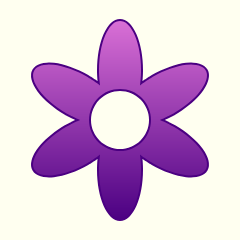

In [2]:
SIZE = 240
CENTER = SIZE / 2
PETALS = 6
FONT = "Arial, Helvetica, sans-serif"

doc = svg.Document(SIZE, SIZE)
paint = svg.LinearGradient.vertical("orchid", "indigo")
doc.rect(0, 0, SIZE, SIZE, fill="ivory")

petal = svg.Ellipse(CENTER, CENTER - 50, 22, 50)
flower = [petal.clone().rotate(360 * i / PETALS, about=(CENTER, CENTER)) for i in range(PETALS)]
blossom = flower[0].union(*flower[1:])
blossom -= svg.Circle(CENTER, CENTER, 30)
doc.path(blossom.d, fill=paint, stroke="indigo", stroke_width=2)
doc

Text takes part too: subtracting a letter from a disc leaves a badge with the letter cut out.

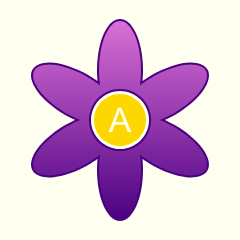

In [3]:
badge = svg.Circle(CENTER, CENTER, 26, fill="gold") - svg.Text("A", x=CENTER, y=CENTER + 12, font_size=34, font_family=FONT, text_anchor="middle")
doc += badge
doc

`stroked(width)` turns a stroke into a filled outline, here a ring around everything.

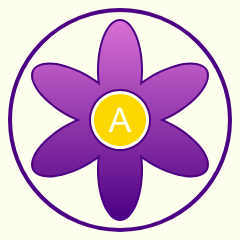

In [4]:
ring = svg.Circle(CENTER, CENTER, 110).stroked(4)
ring.set("fill", "indigo")
doc += ring
doc

Save it. Pass a folder as the first argument to choose where the file goes.

In [5]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
doc.save(out / "boolean_ops.svg")
print("saved boolean_ops.svg")

saved boolean_ops.svg
